# 0. Sobre — Gold Municipal

**Objetivo:** realizar um diagnóstico inicial de estrutura, qualidade, cobertura e distribuição dos dados, antes da integração das bases do Tech Challenge 3.

**Dicionário de dados:** preencher com as definições das variáveis relevantes após inspecionar a base.

**Perguntas norteadoras:** a estrutura está consistente? Há problemas de qualidade? A cobertura é adequada? Há valores atípicos que exigem investigação?

# 1. Configuração e importação de bibliotecas

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

# 2. Carga e inspeção dos dados

Verificar dimensões, tipos de colunas e primeiros registros.

In [3]:
caminho = Path("../data/raw/gold/alfabetizacao_municipio")

df = pd.read_parquet(caminho)

print(f"Linhas: {len(df):,} | Colunas: {df.shape[1]}")
display(df.head())
df.info()

Linhas: 23,995 | Colunas: 47


,serie,rede,id_municipio,taxa_alfabetizacao,media_portugues,proporcao_aluno_nivel_0,proporcao_aluno_nivel_1,proporcao_aluno_nivel_2,proporcao_aluno_nivel_3,proporcao_aluno_nivel_4,...,gap_meta_2030,atingiu_meta_2024,atingiu_meta_2025,atingiu_meta_2026,atingiu_meta_2027,atingiu_meta_2028,atingiu_meta_2029,atingiu_meta_2030,gold_processed_at,ano
0,2,3,2703205,47.93,736.1091,NaN,NaN,NaN,NaN,NaN,...,-32.07,False,False,False,False,False,False,False,2026-10-07 15:37:50.399075,2023
1,2,3,2925956,48.41,733.9164,NaN,NaN,NaN,NaN,NaN,...,-31.59,False,False,False,False,False,False,False,2026-10-07 15:37:50.399075,2023
2,2,5,2932705,30.01,715.2062,NaN,NaN,NaN,NaN,NaN,...,-49.99,False,False,False,False,False,False,False,2026-10-07 15:37:50.399075,2023
3,2,3,3129004,44.72,739.9595,NaN,NaN,NaN,NaN,NaN,...,-35.28,False,False,False,False,False,False,False,2026-10-07 15:37:50.399075,2023
4,2,3,4107553,75.96,763.8896,NaN,NaN,NaN,NaN,NaN,...,-4.04,False,False,False,False,False,False,False,2026-10-07 15:37:50.399075,2023


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23995 entries, 0 to 23994
Data columns (total 47 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   serie                         23995 non-null  int32         
 1   rede                          23995 non-null  int32         
 2   id_municipio                  23995 non-null  object        
 3   taxa_alfabetizacao            23995 non-null  float64       
 4   media_portugues               23995 non-null  float64       
 5   proporcao_aluno_nivel_0       12448 non-null  float64       
 6   proporcao_aluno_nivel_1       12448 non-null  float64       
 7   proporcao_aluno_nivel_2       12448 non-null  float64       
 8   proporcao_aluno_nivel_3       12448 non-null  float64       
 9   proporcao_aluno_nivel_4       12448 non-null  float64       
 10  proporcao_aluno_nivel_5       12448 non-null  float64       
 11  proporcao_aluno_nivel_6     

# 3. Qualidade dos dados

Consolidar valores ausentes e duplicatas em uma única verificação. Diferenciar duplicata exata de repetição de chave de negócio.

In [7]:
qualidade = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "nulos_%": (df.isna().mean() * 100).round(2),
    "valores_unicos": df.nunique(dropna=True)
}).sort_values("nulos_%", ascending=False)

display(qualidade)
print("Linhas duplicadas exatas:", df.duplicated().sum())

,tipo,nulos,nulos_%,valores_unicos
proporcao_aluno_nivel_1,float64,11547,48.12,1374
proporcao_aluno_nivel_0,float64,11547,48.12,943
proporcao_aluno_nivel_6,float64,11547,48.12,2893
proporcao_aluno_nivel_5,float64,11547,48.12,2965
proporcao_aluno_nivel_4,float64,11547,48.12,2620
proporcao_aluno_nivel_3,float64,11547,48.12,2289
proporcao_aluno_nivel_2,float64,11547,48.12,1922
proporcao_aluno_nivel_8,float64,11547,48.12,1404
proporcao_aluno_nivel_7,float64,11547,48.12,2151
gap_meta_2024,float64,1312,5.47,6759


Linhas duplicadas exatas: 0


## 3.1 Chaves e regras de negócio

Validar somente as chaves que representem efetivamente a granularidade da base. **A chave abaixo é uma hipótese de trabalho e deve ser confirmada com o dicionário de dados.**

In [8]:
chave_proposta = ['ano', 'id_municipio', 'rede']
if chave_proposta and all(c in df.columns for c in chave_proposta):
    print("Nulos na chave:", df[chave_proposta].isna().any(axis=1).sum())
    print("Repetições da chave proposta:", df.duplicated(chave_proposta).sum())
else:
    print("Chave não definida ou colunas ausentes: revisar granularidade antes do diagnóstico.")

Nulos na chave: 0
Repetições da chave proposta: 0


In [9]:
numericas = df.select_dtypes(include="number").columns
if len(numericas):
    display(df[numericas].describe().T.round(2))
else:
    print("Nenhuma coluna numérica identificada.")

,count,mean,std,min,25%,50%,75%,max
serie,23995.0,2.00,0.00,2.00,2.00,2.00,2.00,2.00
rede,23995.0,3.73,1.21,0.00,3.00,3.00,5.00,5.00
taxa_alfabetizacao,23995.0,61.44,19.74,2.12,47.17,62.23,76.55,100.00
media_portugues,23995.0,751.38,23.23,673.30,736.04,750.65,764.30,868.46
proporcao_aluno_nivel_0,12448.0,2.20,2.69,0.00,0.00,1.52,3.28,30.00
proporcao_aluno_nivel_1,12448.0,4.31,4.30,0.00,0.83,3.32,6.49,50.00
proporcao_aluno_nivel_2,12448.0,7.73,6.31,0.00,2.85,6.58,11.39,47.06
proporcao_aluno_nivel_3,12448.0,11.27,7.26,0.00,5.76,10.44,16.05,59.73
proporcao_aluno_nivel_4,12448.0,18.27,7.82,0.00,13.33,18.37,23.11,64.71
proporcao_aluno_nivel_5,12448.0,24.22,9.49,0.00,17.78,23.65,30.52,70.00


### Observações de qualidade

- **Inconsistências identificadas:** preencher após executar.
- **Regras adicionais:** aplicar conforme definição oficial dos indicadores; não tratar automaticamente zeros ou negativos como erros.

# 4. Análise exploratória dos dados

Verificar cobertura e visualizar somente os indicadores úteis para esta base.

In [10]:
dimensoes = ['ano', 'id_municipio', 'rede']
for coluna in dimensoes:
    if coluna in df.columns:
        valores = df[coluna].dropna()
        print(f"{coluna}: {valores.nunique():,} valores distintos")
        if coluna == "ano":
            display(df[coluna].value_counts(dropna=False).sort_index().rename("registros"))
        else:
            display(df[coluna].value_counts(dropna=False).head(10).rename("registros"))

ano: 2 valores distintos


ano
2023    11547
2024    12448
Name: registros, dtype: int64

id_municipio: 5,550 valores distintos


id_municipio
2902658    7
2925501    7
2923902    7
2913606    7
2910701    7
2927408    7
4305603    6
3111804    6
3159605    6
2411403    6
Name: registros, dtype: int64

rede: 4 valores distintos


rede
3    10896
5    10466
2     2235
0      398
Name: registros, dtype: int64

## 4.1 Distribuição de taxa de alfabetização

Selecionar um indicador representativo, evitando múltiplos gráficos com a mesma informação.

count    23995.00
mean        61.44
std         19.74
min          2.12
25%         47.17
50%         62.23
75%         76.55
max        100.00
Name: taxa_alfabetizacao, dtype: float64

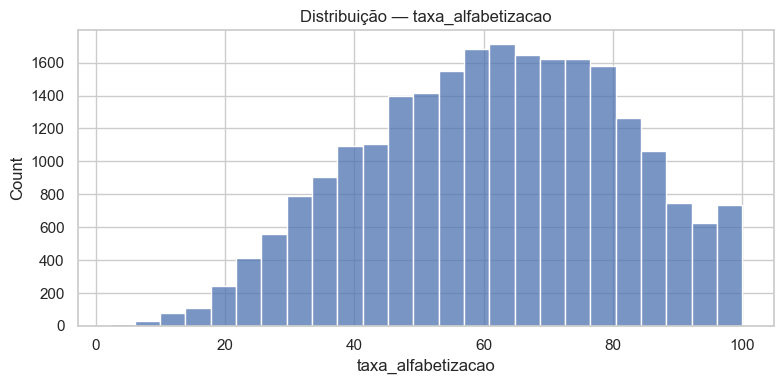

In [11]:
indicador = 'taxa_alfabetizacao'  # substituir se a coluna tiver outro nome
if indicador and indicador in df.columns and pd.api.types.is_numeric_dtype(df[indicador]):
    display(df[indicador].describe().round(2))
    plt.figure(figsize=(8, 4))
    sns.histplot(data=df, x=indicador, bins=25)
    plt.title(f"Distribuição — {indicador}")
    plt.tight_layout()
    plt.show()
else:
    print("Defina um indicador numérico existente para visualizar sua distribuição.")

## 4.2 Validações específicas

Investigar, quando aplicável, percentuais fora da escala, códigos inválidos, cobertura por ano, denominadores ausentes, valores incompatíveis e outliers relevantes. **Evitar regras genéricas não justificadas.**

In [14]:
coluna_taxa = "taxa_alfabetizacao"
if coluna_taxa in df.columns:
    inconsistentes = df[coluna_taxa].notna() & ~df[coluna_taxa].between(0, 100)
    print("Taxas fora do intervalo [0, 100]:", inconsistentes.sum())

Taxas fora do intervalo [0, 100]: 0


# 5. Conclusão geral

**Estrutura e cobertura:** preencher com os achados reais.

**Qualidade dos dados:** listar somente problemas efetivamente encontrados.

**Impacto para a integração:** registrar chaves, diferenças de anos, nível de agregação e ajustes necessários.

**Decisão:** pronta para integração / exige investigação / exige tratamento (definir após execução).